Task3 -**Exploratory Data Analysis**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]=(10,6)


In [ ]:
df = pd.read_csv("../dataset/Telco_Customer_Churn_Dataset_cleaned.csv")

In [ ]:
print("--- SUMMARY STATISTICS (Numerical) ---")
numeric_cols = ['tenure', 'monthlycharges', 'totalcharges']
stats_df = df[numeric_cols].describe().T
stats_df['median'] = df[numeric_cols].median()
stats_df['mode'] = df[numeric_cols].mode().iloc[0]
print(stats_df[['mean', '50%', 'median', 'mode', 'min', 'max']])

--- SUMMARY STATISTICS (Numerical) ---
                       mean      50%   median   mode    min      max
tenure            32.371149    29.00    29.00   1.00   0.00    72.00
monthlycharges    64.761692    70.35    70.35  20.05  18.25   118.75
totalcharges    2279.734304  1394.55  1394.55   0.00   0.00  8684.80


ANALYSE DU CHURN (Proportions)

In [ ]:
print("\n--- TAUX DE CHURN GLOBAL ---")
churn_counts = df['churn'].value_counts()
churn_pct = df['churn'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': churn_counts, 'Percentage (%)': churn_pct.round(2)}))


--- TAUX DE CHURN GLOBAL ---
       Count  Percentage (%)
churn                       
No      5174           73.46
Yes     1869           26.54


Visualisation : Pie chart du Churn

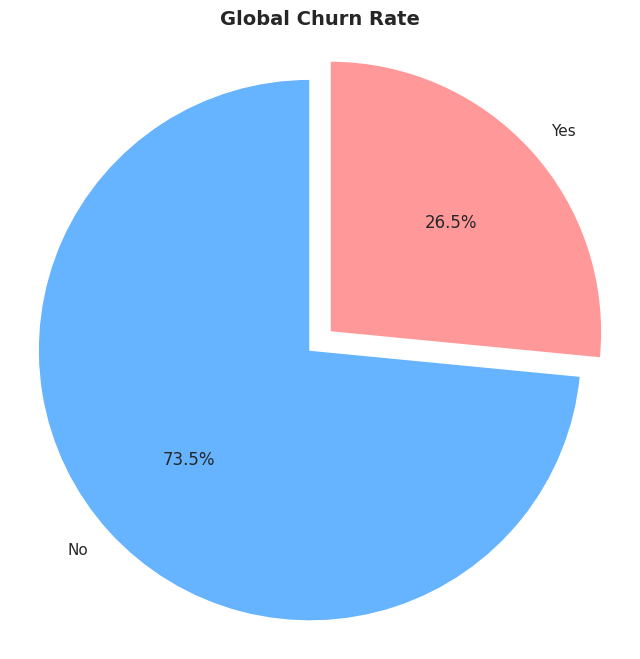

In [ ]:
plt.figure(figsize=(8, 8))
plt.pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%',
        startangle=90, colors=['#66b3ff','#ff9999'], explode=(0, 0.1))
plt.title('Global Churn Rate', fontsize=14,fontweight='bold')
plt.axis('equal')
plt.show()
#

VISUALISATIONS DES VARIABLES NUMÉRIQUES

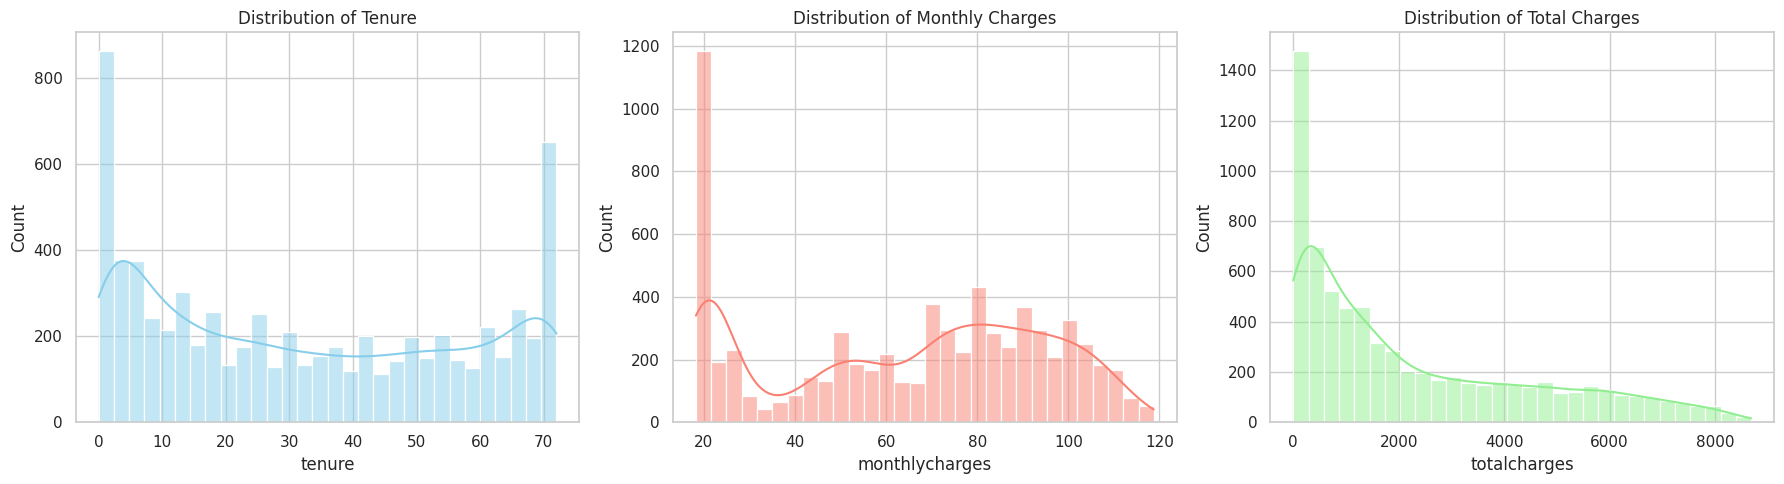

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df['tenure'], bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Tenure')

sns.histplot(df['monthlycharges'], bins=30, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Monthly Charges')

sns.histplot(df['totalcharges'], bins=30, kde=True, ax=axes[2], color='lightgreen')
axes[2].set_title('Distribution of Total Charges')
plt.tight_layout()
plt.show()

Boxplots (Détection de valeurs aberrantes et comparaison avec le Churn)

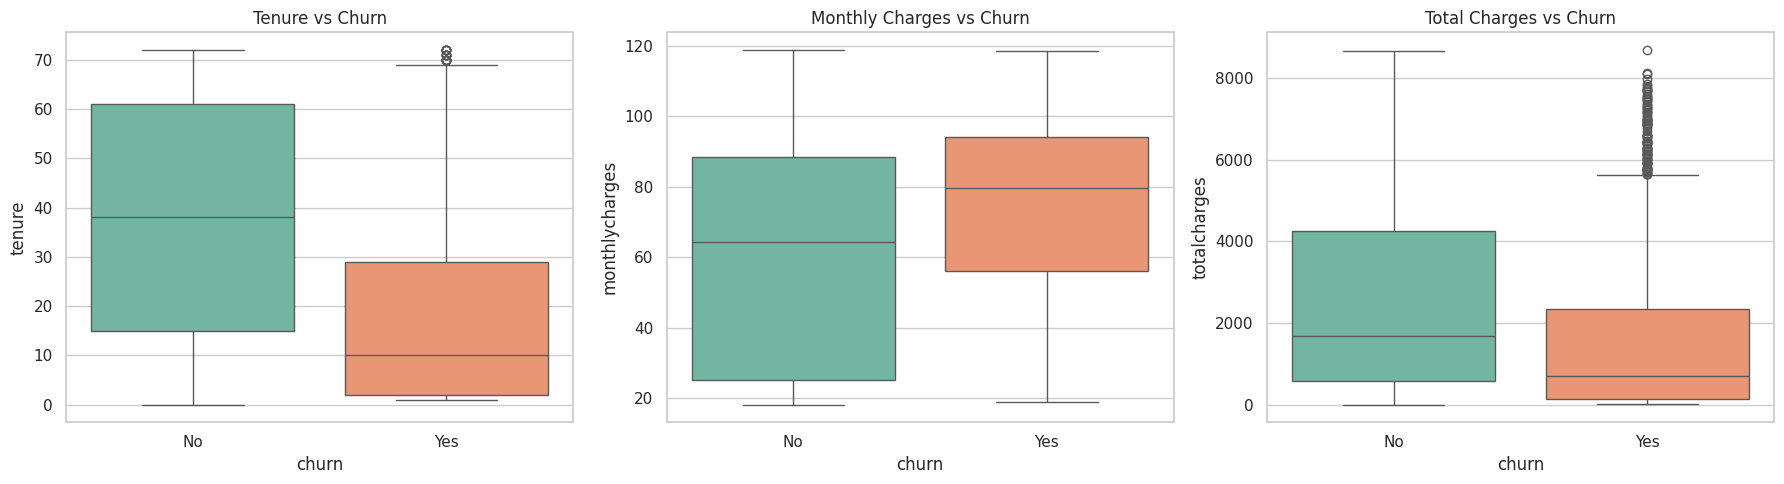

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(x='churn', y='tenure', data=df, ax=axes[0], hue='churn', palette='Set2', legend=False)
axes[0].set_title('Tenure vs Churn')

sns.boxplot(x='churn', y='monthlycharges', data=df, ax=axes[1], hue='churn', palette='Set2', legend=False)
axes[1].set_title('Monthly Charges vs Churn')

sns.boxplot(x='churn', y='totalcharges', data=df, ax=axes[2], hue='churn', palette='Set2', legend=False)
axes[2].set_title('Total Charges vs Churn')

plt.tight_layout()
plt.show()